In [1]:
import numpy as np 
import pandas as pa
import matplotlib.pyplot as plt
import seaborn as se
from tkinter import *
import tkinter as tk
from keras.models import Sequential , load_model
from keras.layers import Dense , Dropout , LSTM , SimpleRNN , RNN , Normalization , Embedding 
from keras.callbacks import EarlyStopping
from keras.preprocessing.text import Tokenizer
from keras.utils import pad_sequences
from sklearn.metrics import accuracy_score , roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import keras.utils as ku
import tensorflow as tf
import keras as ks
%matplotlib widget
#%matplotlib inline

In [2]:
file = pa.read_csv('digikala-comments.csv')
file.head()

,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,26 مرداد 1401,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,28 اسفند 1399,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,12 شهریور 1402,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN


In [3]:
file.describe()

,id,rate,product_id,likes,dislikes
count,6.156289e+06,6.156289e+06,6.156289e+06,6.156289e+06,6.156289e+06
mean,3.704709e+07,3.648286e+00,3.908983e+06,4.503171e-01,8.687068e-02
std,1.393243e+07,1.861854e+00,3.015881e+06,2.294114e+00,8.313516e-01
min,9.815860e+05,0.000000e+00,7.602000e+03,0.000000e+00,0.000000e+00
25%,2.731234e+07,3.000000e+00,1.532375e+06,0.000000e+00,0.000000e+00
50%,4.044773e+07,4.000000e+00,3.183184e+06,0.000000e+00,0.000000e+00
75%,4.897122e+07,5.000000e+00,5.992988e+06,0.000000e+00,0.000000e+00
max,5.474516e+07,2.500000e+03,1.270221e+07,1.136000e+03,3.360000e+02


In [4]:
file.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6156289 entries, 0 to 6156288
Data columns (total 15 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   id                     int64  
 1   title                  object 
 2   body                   object 
 3   created_at             object 
 4   rate                   float64
 5   recommendation_status  object 
 6   is_buyer               bool   
 7   product_id             int64  
 8   advantages             object 
 9   disadvantages          object 
 10  likes                  int64  
 11  dislikes               int64  
 12  seller_title           object 
 13  seller_code            object 
 14  true_to_size_rate      object 
dtypes: bool(1), float64(1), int64(4), object(9)
memory usage: 663.4+ MB


In [5]:
file['recommendation_status'].value_counts()

recommendation_status
recommended        4162839
no_idea             594121
not_recommended     504903
Name: count, dtype: int64

In [6]:
file = file[~file['body'].isna()]
file = file[~file['recommendation_status'].isna()]

In [7]:
x_file_recommendation_status = [0 if i == 'not_recommended' else 1 if i == 'no_idea' else 2 for i in file['recommendation_status']]

In [8]:
print(x_file_recommendation_status[:20])
print(len(x_file_recommendation_status))

[0, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 0, 2, 2, 1, 2]
5261362


In [9]:
file.head()

,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,26 مرداد 1401,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,28 اسفند 1399,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,12 شهریور 1402,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN


In [10]:
array_text = []
array_text.extend(list(file.body.values))

In [11]:
array_text

['به درد نمیخوره ',
 'می\u200cتونست به عنوان یه کالای فرهنگی بهتر بسته بندی بشه',
 'بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خوبه من برای روغن زدم به مژه و لیفت ابرو خریدم',
 'به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد من برای صابون ابرو استفاده میکنم راضی ام',
 'معمولیه اگه واسه خونه رنگ کردن شخصی میخواین اوکیه ولی اگه واسه کار دکلره میخواین نه زیاد ولی خوبه',
 'قبلا هم استفاده کردم اگه بلد باشین کار کردن باهاش رو \r\nبرای ی پاکسازی پوست سطحی توی خونه عالیه',
 'خیلی به کارتون میاد قیمتشم مناسبه',
 'دقیقا مطابق عکس بود',
 'برا حالت دادن با اسپری یا پودر عالیه',
 'اندازش کوچیکه بدرد رنگ مو نمیخوره ',
 'مطابق توضیحات بود',
 'لب ھارو نرم میکنہ و قیمت مناسب',
 'خوب بود   بخرید قشنگه',
 'سالم بود،شستنش راحته،واسه ماسک گذاشتن خیلی ایده ی خوبیه،از اسراف و کثیف کاری قشنگ جلوگیری میکنه.',
 'خیلی عالی بود ، کاربردیه ، دیگه لازم نیست جوشا رو دستکاری کرد ، با این پیلینگ خیلی راحت میشه تخلیه کرد',
 'بدرد نخور واقعی وقتی بدستم رسید برسش کج بود و نامنظم و از هرطرف زده بود بیرون مرجوع کردم',
 '

In [12]:
tokenizer = Tokenizer(num_words=20000,oov_token='<OOV>')
tokenizer.fit_on_texts(array_text)

token_list = tokenizer.texts_to_sequences(array_text)
token_list = pad_sequences(token_list,maxlen=100,padding='post')

In [21]:
import pickle

with open('tokenizer.pkl', 'wb') as file:
    pickle.dump(tokenizer, file)

In [13]:
file.head()

,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بن...,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خ...,26 مرداد 1401,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد ...,28 اسفند 1399,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین او...,12 شهریور 1402,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN


In [14]:
X = token_list
Y = x_file_recommendation_status

In [15]:
X

array([[   6,  219,  434, ...,    0,    0,    0],
       [5523,    6,  322, ...,    0,    0,    0],
       [  69,  605,    5, ...,    0,    0,    0],
       ...,
       [  29,    0,    0, ...,    0,    0,    0],
       [  14,   18,    2, ...,    0,    0,    0],
       [   1,  285,  456, ...,    0,    0,    0]])

In [16]:
Y

[0,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 0,
 2,
 2,
 2,
 2,
 2,
 0,
 2,
 2,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 0,
 2,
 2,
 2,
 0,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 1,
 2,
 2,
 2,
 2,
 2,
 0,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 0,
 2,
 2,
 1,
 0,
 2,
 2,
 2,
 1,
 2,
 2,
 2,
 2,
 2,
 1,
 2,
 0,
 2,
 1,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 0,
 0,
 2,
 2,
 0,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 0,
 0,
 0,
 2,
 2,
 0,
 0,
 2,
 2,
 1,
 2,
 1,
 1,
 2,
 2,
 2,
 1,
 2,
 2,
 0,
 0,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 1,
 2,
 2,
 2,
 2,
 1,
 2,
 1,
 2,
 2,
 2,
 2,
 1,
 2,
 1,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 1,
 2,
 2,
 2,
 2,
 2,
 0,
 1,
 2,
 2,
 2,
 1,
 2,
 2,
 1,
 0,
 2,
 1,
 2,
 2,
 0,
 2,
 0,
 2,
 2,
 2,
 2,
 2,
 2,
 0,
 2,
 1,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 0,
 2,
 1,
 2,
 1,
 0,
 2,
 0,
 2,
 0,
 1,
 1,
 2,
 2,
 2,
 2,
 0,
 2,
 2,
 2,
 2,
 2,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 1,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,
 2,


In [17]:
X_train , X_test , Y_train , Y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

print("X_train",X_train.shape)
print("X_test",X_test.shape)
print()
print('Y_train',len(Y_train))
print('Y_test',len(Y_test))

X_train (4209089, 100)
X_test (1052273, 100)

Y_train 4209089
Y_test 1052273


In [18]:
model = load_model('model_digikala_comment.h5')

In [18]:
model = Sequential()

model.add(Embedding(20000,128,input_length=100))
model.add(LSTM(64))
model.add(Dropout(0.5))
model.add(Dense(3,activation='softmax'))
model.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),optimizer='adam',metrics=['accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 100, 128)          2560000   
                                                                 
 lstm (LSTM)                 (None, 64)                49408     
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 3)                 195       
                                                                 
Total params: 2,609,603
Trainable params: 2,609,603
Non-trainable params: 0
_________________________________________________________________


In [19]:
class_weights = compute_class_weight('balanced',classes=np.unique(Y_train),y=Y_train)
class_weights_dict = dict(enumerate(class_weights))
print(class_weights_dict)

{0: 3.476907839522082, 1: 2.9526588449869346, 2: 0.42128139701123735}


In [20]:
Y_train = np.array(Y_train)
Y_test = np.array(Y_test)

print(Y_train.shape)
print(Y_test.shape)

(4209089,)
(1052273,)


In [46]:
model.fit(X_train,Y_train,validation_data=(X_test,Y_test),class_weight=class_weights_dict,batch_size=64,epochs=1)

65768/65768 [==============================] - 7101s 108ms/step - loss: 0.5768 - accuracy: 0.8148 - val_loss: 0.4816 - val_accuracy: 0.8122


In [21]:
out_robot = model.predict(X_test)


32884/32884 [==============================] - 466s 14ms/step


In [22]:
print(out_robot[:10])
print()      
print(Y_test[:10])

[[0.00553391 0.01510124 0.9793649 ]
 [0.00925357 0.05667935 0.9340671 ]
 [0.9218514  0.07383784 0.00431076]
 [0.42302373 0.35930094 0.2176753 ]
 [0.00730974 0.01826377 0.9744265 ]
 [0.00749227 0.05104098 0.94146675]
 [0.01515358 0.09917034 0.885676  ]
 [0.00941978 0.07876813 0.91181207]
 [0.01902889 0.1016405  0.8793306 ]
 [0.3305224  0.46619737 0.20328023]]

[2 2 0 2 2 2 2 2 2 2]


In [23]:
loss , acc = model.evaluate(X_test,Y_test)
print(acc)

    1/32884 [..............................] - ETA: 4:12:18 - loss: 0.6319 - accuracy: 0.6875

D:\lib\site-packages\keras\backend.py:5612: UserWarning: "`sparse_categorical_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Softmax activation and thus does not represent logits. Was this intended?
  output, from_logits = _get_logits(


32884/32884 [==============================] - 549s 17ms/step - loss: 0.4816 - accuracy: 0.8122
0.812234103679657


In [24]:
array = out_robot[:100].tolist()
result = []
for i in array :
    result.append(i.index(max(i)))
print(result)
print()
print(Y_test[:100])    
    

[2, 2, 0, 0, 2, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1, 2, 1, 1, 1, 1, 2, 2, 2, 2, 0, 0, 0, 1, 0, 2, 2, 2, 1, 1, 0, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 1, 1, 2, 0, 1, 2, 2, 2, 2, 0, 2, 2, 1, 2, 1, 2, 2, 0, 2, 1, 0, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 1, 0, 1, 2, 2, 2, 0, 2, 2, 2]

[2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 0 2 2 1 2 2 1 0 0 1 0 2 2 2 1 1 1
 2 2 2 2 2 2 2 1 2 2 1 2 2 2 2 2 2 2 2 0 2 2 2 1 2 0 2 2 1 2 2 2 2 0 2 1 0
 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 0 1 2 2 2 0 2 2 2]


In [50]:
model.save('model_digikala_comment.h5')

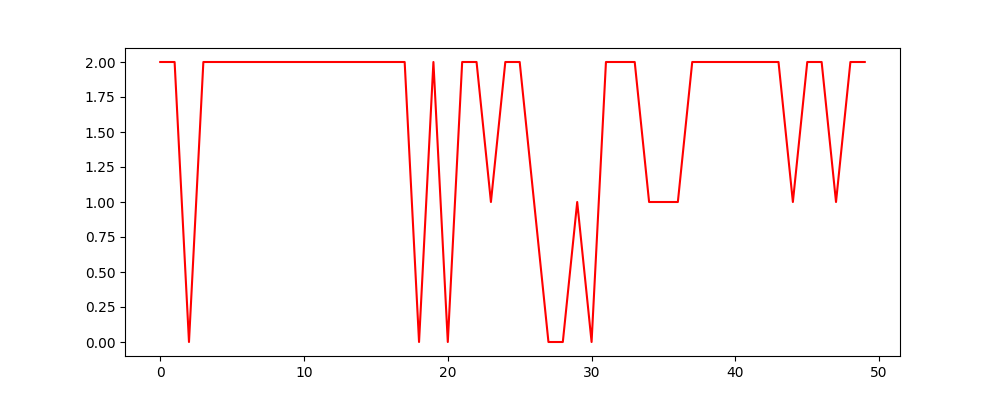

In [25]:
plt.close()
plt.figure(figsize=(10,4))
plt.plot(Y_test[:50],color='red')
plt.show()

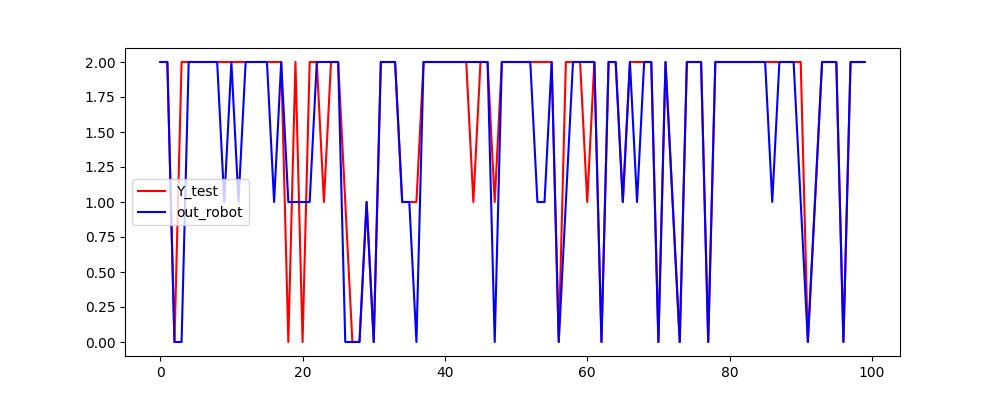

In [26]:
plt.close()
plt.figure(figsize=(10,4))
plt.plot(Y_test[:100],color='red')
plt.plot(result,color='blue')
plt.legend(['Y_test','out_robot'])
plt.show()

[2 2 0 2 2 2 2 2 2 2]


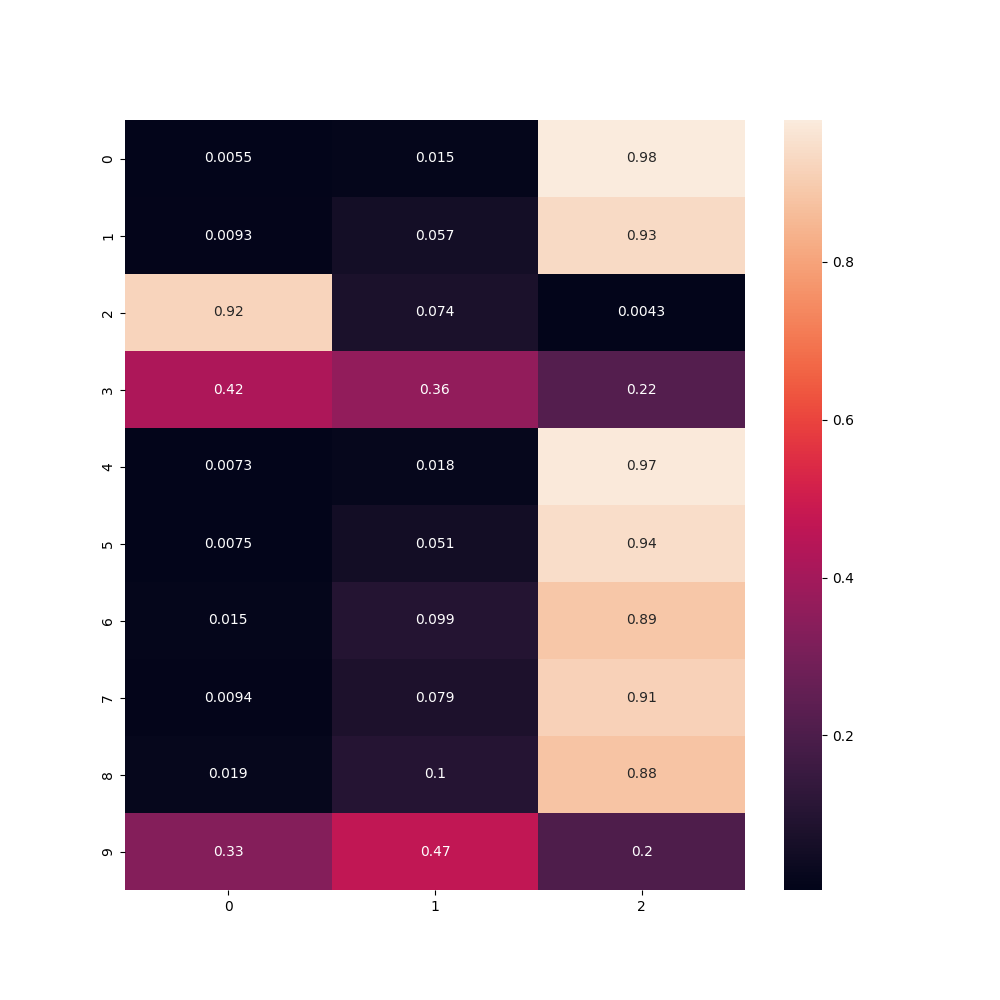

In [27]:
plt.close()
plt.figure(figsize=(10,10))
se.heatmap(out_robot[:10],annot=True)
print(Y_test[:10])



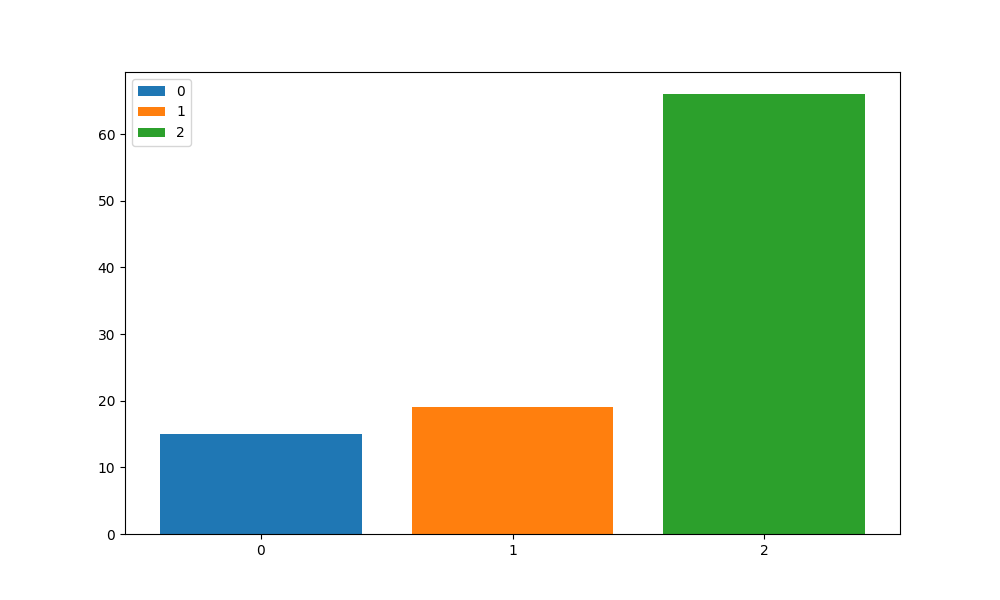

In [28]:
plt.close()
values , counts = np.unique(result,return_counts=True)
plt.figure(figsize=(10,6))
plt.bar(values[0],counts[0])
plt.bar(values[1],counts[1])
plt.bar(values[2],counts[2])
plt.legend(['0','1','2'])
plt.xticks([0,1,2])
plt.show()

In [29]:
input_user = input('please enter your massage :')
def generator_text(input_user,model) :
    text_list = []

    text_list.append(input_user)
    tokenizer.fit_on_texts(text_list) 
    token_list2 = tokenizer.texts_to_sequences(text_list)
    token_list2 = pad_sequences(token_list2,maxlen=100,padding='post')

    X_predict = model.predict(token_list2)

    return X_predict

out = generator_text(input_user,model)
print(out)
array2 = out.tolist()
result2 = []
for i in array2 :
    result2.append(i.index(max(i)))
print(input_user)
print(result2)


1/1 [==============================] - 0s 27ms/step
[[0.01056584 0.1432462  0.84618795]]
من از این کالا راضی هستم
[2]


In [37]:
root = Tk()

rootw = 900
rooth = 450

screenw = root.winfo_screenwidth()
screenh = root.winfo_screenheight()

loacationw = int((screenw / 2) - (rootw / 2))
loacationh = int((screenh / 2) - (rooth / 2))

root.geometry(f'{rootw}x{rooth}+{loacationw}+{loacationh}')

def token_text(models) :
    text = text_edit.get('1.0', END)
    lister = []

    lister.append(text)

    tok = tokenizer.texts_to_sequences(lister)
    tok = pad_sequences(tok,maxlen=100,padding='post')

    x_predect = models.predict(tok)

    array = x_predect.tolist()
    result = []
    for i in array :
        result.append(i.index(max(i)))

    return result

def generation() :
    text = token_text(model)
    out1 = "👍"
    out2 = "🤙"
    out3 = "👎"
    if text[0] == 0 :
        label['text'] = out3
    elif text[0] == 1 :
        label['text'] = out2
    elif text[0] == 2 :
        label['text'] = out1

def text():
    label['text'] = 'hi'

text_edit = Text(root,width=50,height=10,bd=3,border=5)
button = Button(root,text='tokenizered',bd=3,foreground='white',background='black',border=5,command=lambda : token_text(model))
button2 = Button(root,text='prediction',bd=3,foreground='white',background='black',border=5,command=generation)
label = Label(root,text='Welcome',foreground='black',font=('Ehsan',30))
label2 = Label(root,text="""⚠️ please first click in button tokenizered 
and click button prediction""",font=('Ehsan',10),foreground='red',background='black')


button.place(x=150,y=70)
button2.place(x=150,y=120)
label2.place(x=50,y=200)
text_edit.place(x=250,y=10)
label.place(x=450,y=200)


root.mainloop()

1/1 [==============================] - 0s 18ms/step
